In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import patsy

df = pd.read_csv("data/london_merged_daily.csv", parse_dates=["date"])
df["time"] = np.arange(len(df))           # day counter for the trend/season spline
df["dow"] = df["date"].dt.day_name()      # day of week
n_years = df["date"].dt.year.nunique()
print(len(df), "days,", n_years, "years")

1826 days, 5 years


In [2]:
def fit_temperature_model(data, temp_col, df_temp=4, df_time_per_year=7):
    rhs = (f"cr({temp_col}, df={df_temp}, constraints='center')"
           f" + cr(time, df={df_time_per_year * n_years}, constraints='center') + C(dow)")
    X = patsy.dmatrix(rhs, data, return_type="dataframe")
    model = sm.GLM(data["numdeaths"], X, family=sm.families.Poisson()).fit(scale="X2")
    return model, X.design_info

In [3]:
def exposure_response(model, design_info, data, temp_col):
    grid = np.round(np.arange(data[temp_col].quantile(0.01), data[temp_col].quantile(0.99), 0.1), 1)
    new = pd.DataFrame({temp_col: grid, "time": 0, "dow": data["dow"].iloc[0]})
    X = patsy.build_design_matrices([design_info], new, return_type="dataframe")[0]
    cols = [c for c in X.columns if c.startswith(f"cr({temp_col}")]
    Xt = X[cols].to_numpy()
    b = model.params[cols].to_numpy()
    V = model.cov_params().loc[cols, cols].to_numpy()
    i_mmt = np.argmin(Xt @ b)                 # lowest-risk temperature
    D = Xt - Xt[i_mmt]                        # contrast with the minimum
    est = D @ b
    se = np.sqrt(np.einsum("ij,jk,ik->i", D, V, D))
    curve = pd.DataFrame({"temp": grid, "rr": np.exp(est),
                          "low": np.exp(est - 1.96 * se), "high": np.exp(est + 1.96 * se)})
    return curve, grid[i_mmt]

overdispersion: 1.2 1.19
MMT station: 5.5 | MMT ERA5: 4.4
station: 99th pct 24.0 °C, RR 1.28 (1.23-1.32)
ERA5: 99th pct 22.3 °C, RR 1.28 (1.23-1.32)


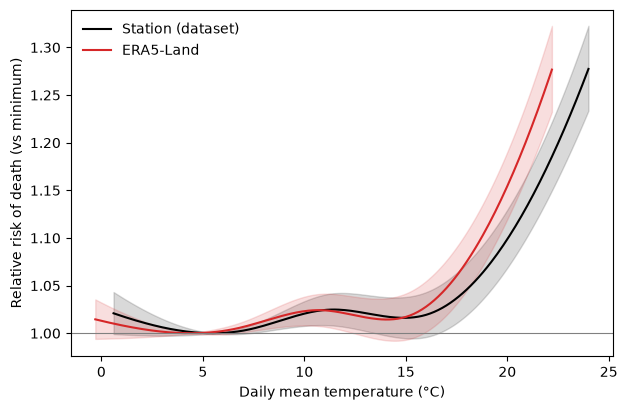

In [4]:
m_obs, di_obs = fit_temperature_model(df, "temperature")
m_era, di_era = fit_temperature_model(df, "era5_tmean")
print("overdispersion:", round(m_obs.scale, 2), round(m_era.scale, 2))

curve_obs, mmt_obs = exposure_response(m_obs, di_obs, df, "temperature")
curve_era, mmt_era = exposure_response(m_era, di_era, df, "era5_tmean")
print("MMT station:", mmt_obs, "| MMT ERA5:", mmt_era)

for name, curve, col in [("station", curve_obs, "temperature"), ("ERA5", curve_era, "era5_tmean")]:
    p99 = df[col].quantile(0.99)
    row = curve.iloc[(curve["temp"] - p99).abs().argmin()]
    print(f"{name}: 99th pct {p99:.1f} °C, RR {row.rr:.2f} ({row.low:.2f}-{row.high:.2f})")

fig, ax = plt.subplots(figsize=(7, 4.5))
for curve, label, colour in [(curve_obs, "Station (dataset)", "black"), (curve_era, "ERA5-Land", "tab:red")]:
    ax.plot(curve["temp"], curve["rr"], color=colour, label=label)
    ax.fill_between(curve["temp"], curve["low"], curve["high"], color=colour, alpha=0.15)
ax.axhline(1, color="grey", lw=0.8)
ax.set_xlabel("Daily mean temperature (°C)")
ax.set_ylabel("Relative risk of death (vs minimum)")
ax.legend(frameon=False)
fig.savefig("figures/exposure_response_lag0.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
MAX_LAG = 21

def lag_matrix(x, max_lag=MAX_LAG):
    """n x (L+1) matrix: column l holds temperature l days earlier."""
    x = np.asarray(x, dtype=float)
    Q = np.full((len(x), max_lag + 1), np.nan)
    for lag in range(max_lag + 1):
        Q[lag:, lag] = x[: len(x) - lag]
    return Q

def exposure_basis_info(x):
    """Natural spline for temperature, knots at the 10th, 75th and 90th percentiles."""
    knots = np.percentile(x, [10, 75, 90])
    lo, hi = x.min(), x.max()
    formula = (f"cr(x, knots=[{knots[0]}, {knots[1]}, {knots[2]}], "
               f"lower_bound={lo}, upper_bound={hi}, constraints='center') - 1")
    return patsy.dmatrix(formula, {"x": np.linspace(lo, hi, 100)}).design_info

def exposure_basis(info, values):
    return np.asarray(patsy.build_design_matrices([info], {"x": np.asarray(values, dtype=float)})[0])

def lag_basis(max_lag=MAX_LAG, n_knots=3):
    """Natural spline over lags, knots equally spaced on the log scale (like dlnm's logknots)."""
    knots = np.exp(np.linspace(0, np.log(max_lag + 1), n_knots + 2))[1:-1] - 1
    k = ", ".join(f"{v:.4f}" for v in knots)
    lags = np.arange(max_lag + 1, dtype=float)
    return np.asarray(patsy.dmatrix(f"cr(lag, knots=[{k}], lower_bound=0, upper_bound={max_lag}) - 1", {"lag": lags}))

def crossbasis(x, info, LB):
    """Combine the temperature basis (applied to every lag) with the lag basis."""
    Q = lag_matrix(x)
    ok = ~np.isnan(Q).any(axis=1)
    n_lag = Q.shape[1]
    Bx = exposure_basis(info, Q[ok].ravel()).reshape(ok.sum(), n_lag, -1)
    cb = np.full((len(x), Bx.shape[2] * LB.shape[1]), np.nan)
    cb[ok] = np.einsum("tli,lj->tij", Bx, LB).reshape(ok.sum(), -1)
    return cb

In [6]:
def fit_dlnm(data, temp_col):
    x = data[temp_col].to_numpy()
    info = exposure_basis_info(x)
    LB = lag_basis()
    cb = crossbasis(x, info, LB)
    conf = patsy.dmatrix(f"cr(time, df={7 * n_years}, constraints='center') + C(dow)",
                         data, return_type="dataframe")
    X = np.column_stack([cb, conf.to_numpy()])
    keep = ~np.isnan(X).any(axis=1)          # first 21 days have no full lag history
    model = sm.GLM(data["numdeaths"].to_numpy()[keep], X[keep],
                   family=sm.families.Poisson()).fit(scale="X2")
    k = cb.shape[1]
    return {"info": info, "LB": LB, "coef": model.params[:k], "vcov": model.cov_params()[:k, :k],
            "x": x, "scale": model.scale}

def predict_overall(fit, at, ref):
    """Cumulative RR over lags 0-21 at temperatures `at`, relative to `ref`."""
    D = exposure_basis(fit["info"], at) - exposure_basis(fit["info"], [ref])
    rows = np.einsum("ni,j->nij", D, fit["LB"].sum(axis=0)).reshape(len(at), -1)
    est = rows @ fit["coef"]
    se = np.sqrt(np.einsum("ij,jk,ik->i", rows, fit["vcov"], rows))
    return np.exp(est), np.exp(est - 1.96 * se), np.exp(est + 1.96 * se)

def predict_lag(fit, value, ref):
    """RR at each lag for temperature `value` relative to `ref`."""
    d = (exposure_basis(fit["info"], [value]) - exposure_basis(fit["info"], [ref]))[0]
    rows = np.einsum("i,lj->lij", d, fit["LB"]).reshape(fit["LB"].shape[0], -1)
    est = rows @ fit["coef"]
    se = np.sqrt(np.einsum("ij,jk,ik->i", rows, fit["vcov"], rows))
    return np.exp(est), np.exp(est - 1.96 * se), np.exp(est + 1.96 * se)

def find_mmt(fit):
    """Minimum-mortality temperature, searched between the 1st and 99th percentiles."""
    lo, hi = np.percentile(fit["x"], [1, 99])
    grid = np.round(np.arange(lo, hi, 0.1), 1)
    rr, _, _ = predict_overall(fit, grid, ref=grid[0])
    return grid[np.argmin(rr)]

In [7]:
results = {}
for name, col in [("Station", "temperature"), ("ERA5-Land", "era5_tmean")]:
    fit = fit_dlnm(df, col)
    mmt = find_mmt(fit)
    p01, p99 = np.percentile(fit["x"], [1, 99])
    grid = np.round(np.arange(np.percentile(fit["x"], 0.5), np.percentile(fit["x"], 99.5), 0.1), 1)
    rr, low, high = predict_overall(fit, grid, ref=mmt)
    results[name] = dict(fit=fit, mmt=mmt, p01=p01, p99=p99, grid=grid, rr=rr, low=low, high=high)
    hot = predict_overall(fit, [p99], ref=mmt)
    cold = predict_overall(fit, [p01], ref=mmt)
    print(f"{name}: overdispersion {fit['scale']:.2f} | MMT {mmt:.1f} °C | "
          f"heat (99th, {p99:.1f} °C) RR {hot[0][0]:.2f} ({hot[1][0]:.2f}-{hot[2][0]:.2f}) | "
          f"cold (1st, {p01:.1f} °C) RR {cold[0][0]:.2f} ({cold[1][0]:.2f}-{cold[2][0]:.2f})")

Station: overdispersion 1.04 | MMT 18.9 °C | heat (99th, 24.0 °C) RR 1.36 (1.27-1.46) | cold (1st, 0.6 °C) RR 1.50 (1.38-1.63)
ERA5-Land: overdispersion 1.05 | MMT 17.7 °C | heat (99th, 22.3 °C) RR 1.33 (1.25-1.42) | cold (1st, -0.3 °C) RR 1.47 (1.35-1.60)


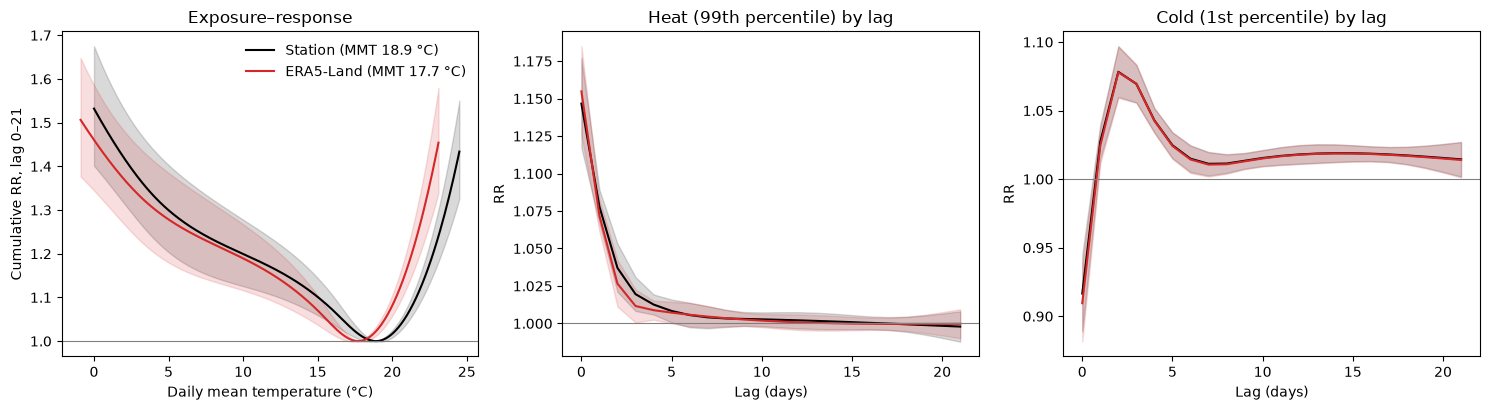

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
colours = {"Station": "black", "ERA5-Land": "tab:red"}

for name, r in results.items():
    axes[0].plot(r["grid"], r["rr"], color=colours[name], label=f"{name} (MMT {r['mmt']:.1f} °C)")
    axes[0].fill_between(r["grid"], r["low"], r["high"], color=colours[name], alpha=0.15)
axes[0].set(xlabel="Daily mean temperature (°C)", ylabel="Cumulative RR, lag 0–21", title="Exposure–response")
axes[0].legend(frameon=False)

for ax, which, title in [(axes[1], "p99", "Heat (99th percentile) by lag"),
                         (axes[2], "p01", "Cold (1st percentile) by lag")]:
    for name, r in results.items():
        rr, low, high = predict_lag(r["fit"], r[which], ref=r["mmt"])
        ax.plot(range(MAX_LAG + 1), rr, color=colours[name], label=name)
        ax.fill_between(range(MAX_LAG + 1), low, high, color=colours[name], alpha=0.15)
    ax.set(xlabel="Lag (days)", ylabel="RR", title=title)

for ax in axes:
    ax.axhline(1, color="grey", lw=0.8)
fig.tight_layout()
fig.savefig("figures/dlnm_station_vs_era5.png", dpi=150, bbox_inches="tight")
plt.show()